# Parte 1. Validación de los intervalos de confianza mediante bootstrap

**Resultados de la S1 que se validan:** los IC 95 % clásicos de la Tabla 5 del informe de la S1 y las
diferencias de presión sistólica y de glucosa de la Tabla 4. La diferencia de presión sistólica se incluye
a pedido del docente en la retroalimentación de la S1, y la de glucosa por ser la variable más asimétrica.

| Parámetro | Estimación S1 | IC 95 % S1 | Método S1 |
| --- | --- | --- | --- |
| Edad media (años) | 49,58 | [49,32; 49,84] | t de Student |
| Presión sistólica media (mmHg) | 132,35 | [131,69; 133,02] | t de Student |
| Colesterol total medio (mg/dL), n = 4.190 | 236,70 | [235,35; 238,05] | t de Student |
| Proporción de CHD a 10 años (%) | 15,19 | [14,14; 16,30] | Wilson |
| Diferencia de presión sistólica CHD − sin CHD (mmHg) | 13,28 | [11,11; 15,45] | Welch |
| Diferencia de glucosa CHD − sin CHD (mg/dL) | 8,33 | [4,95; 11,71] | Welch |

Para cada parámetro se generan 10.000 remuestras, se calculan los IC percentil y BCa, se grafica la
distribución bootstrap y se compara con el IC clásico de la S1.

## Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from utils_s2 import (
    SEED, B, ALPHA, FIG, RESULTADOS_S1, NOMBRES, NUM, COLORES,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla,
    ic_bootstrap, p_valor_permutacion, jackknife, media_acumulada,
)

configurar_graficos()
rng = np.random.default_rng(SEED)
df = cargar_datos()
print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]} | B = {B:,} | semilla = {SEED}")

Observaciones: 4240 | Variables: 16 | B = 10,000 | semilla = 42


In [2]:
# Los datos deben reproducir las cifras de la S1
assert round(df["age"].mean(), 2) == RESULTADOS_S1["ic"]["edad_media"]["estimacion"]
assert round(df["sysBP"].mean(), 2) == RESULTADOS_S1["ic"]["sysbp_media"]["estimacion"]
assert round(df["totChol"].mean(), 2) == RESULTADOS_S1["ic"]["colesterol_media"]["estimacion"]
assert round(df["TenYearCHD"].mean() * 100, 2) == RESULTADOS_S1["ic"]["prop_chd_%"]["estimacion"]
print("OK: los datos coinciden con la Sumativa 1")

OK: los datos coinciden con la Sumativa 1


## 1.1 Bootstrap de cada parámetro

Se generan 10.000 remuestras con reemplazo para cada estimador. En la proporción, la variable
`TenYearCHD` se trata como indicador 0/1; para colesterol se usan casos observados. La diferencia de
glucosa se calcula remuestreando de forma independiente los grupos con y sin CHD. A partir de una
misma distribución bootstrap se obtienen el IC percentil y el IC BCa; la aceleración de BCa se estima
mediante jackknife.

In [3]:
def diferencia_medias(a, b, axis=-1):
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)


def distribucion_bootstrap_media(muestras, n_resamples=B, seed=SEED, batch=2_000):
    """Distribución bootstrap de una media o diferencia de medias, por lotes."""
    muestras = tuple(np.asarray(x, dtype=float) for x in muestras)
    rng_local = np.random.default_rng(seed)
    distribucion = np.empty(n_resamples)
    inicio = 0
    while inicio < n_resamples:
        m = min(batch, n_resamples - inicio)
        medias = []
        for x in muestras:
            indices = rng_local.integers(0, len(x), size=(m, len(x)))
            medias.append(x[indices].mean(axis=1))
        distribucion[inicio:inicio + m] = medias[0] if len(medias) == 1 else medias[0] - medias[1]
        inicio += m
    return distribucion


def jackknife_media(muestras):
    """Estimaciones leave-one-out para la corrección de aceleración BCa."""
    if len(muestras) == 1:
        x = np.asarray(muestras[0], dtype=float)
        return (x.sum() - x) / (len(x) - 1)
    a, b = (np.asarray(x, dtype=float) for x in muestras)
    jack_a = (a.sum() - a) / (len(a) - 1) - b.mean()
    jack_b = a.mean() - (b.sum() - b) / (len(b) - 1)
    return np.concatenate([jack_a, jack_b])


def intervalo_bca(distribucion, estimacion, jackknife, alpha=ALPHA):
    """IC BCa de Efron a partir de una distribución y valores jackknife."""
    proporcion = (np.sum(distribucion < estimacion) + .5 * np.sum(distribucion == estimacion)) / len(distribucion)
    proporcion = np.clip(proporcion, 1 / (2 * len(distribucion)), 1 - 1 / (2 * len(distribucion)))
    z0 = stats.norm.ppf(proporcion)
    diferencias = jackknife.mean() - jackknife
    aceleracion = np.sum(diferencias ** 3) / (6 * np.sum(diferencias ** 2) ** 1.5)
    z = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    probabilidades = stats.norm.cdf(z0 + (z0 + z) / (1 - aceleracion * (z0 + z)))
    return np.quantile(distribucion, probabilidades)


def calcular_intervalos(nombre, muestras, estadistico, escala, referencia_s1, n_efectivo):
    """Calcula IC percentil y BCa con una única serie de 10.000 remuestras."""
    dist_sin_escala = distribucion_bootstrap_media(muestras, n_resamples=B, seed=SEED)
    estimacion_sin_escala = estadistico(*muestras, axis=-1)
    p_inf, p_sup = np.quantile(dist_sin_escala, [ALPHA / 2, 1 - ALPHA / 2])
    b_inf, b_sup = intervalo_bca(
        dist_sin_escala, estimacion_sin_escala, jackknife_media(muestras)
    )
    dist = dist_sin_escala * escala
    estimacion = estadistico(*muestras, axis=-1) * escala
    return {
        "Parámetro": nombre,
        "n": n_efectivo,
        "Estimación": float(estimacion),
        "S1_inf": referencia_s1[0],
        "S1_sup": referencia_s1[1],
        "Percentil_inf": float(p_inf * escala),
        "Percentil_sup": float(p_sup * escala),
        "BCa_inf": float(b_inf * escala),
        "BCa_sup": float(b_sup * escala),
        "Distribución": np.asarray(dist, dtype=float),
    }


edad = df["age"].dropna().to_numpy()
pas = df["sysBP"].dropna().to_numpy()
colesterol = df["totChol"].dropna().to_numpy()
chd = df["TenYearCHD"].dropna().to_numpy()
pas_chd = df.loc[df["TenYearCHD"] == 1, "sysBP"].dropna().to_numpy()
pas_no = df.loc[df["TenYearCHD"] == 0, "sysBP"].dropna().to_numpy()
glu_chd = df.loc[df["TenYearCHD"] == 1, "glucose"].dropna().to_numpy()
glu_no = df.loc[df["TenYearCHD"] == 0, "glucose"].dropna().to_numpy()

resultados = [
    calcular_intervalos(
        "Edad media (años)", (edad,), np.mean, 1,
        RESULTADOS_S1["ic"]["edad_media"]["ic"], len(edad)
    ),
    calcular_intervalos(
        "PAS media (mmHg)", (pas,), np.mean, 1,
        RESULTADOS_S1["ic"]["sysbp_media"]["ic"], len(pas)
    ),
    calcular_intervalos(
        "Colesterol medio (mg/dL)", (colesterol,), np.mean, 1,
        RESULTADOS_S1["ic"]["colesterol_media"]["ic"], len(colesterol)
    ),
    calcular_intervalos(
        "Proporción CHD (%)", (chd,), np.mean, 100,
        RESULTADOS_S1["ic"]["prop_chd_%"]["ic"], len(chd)
    ),
    calcular_intervalos(
        "Diferencia PAS CHD − no CHD", (pas_chd, pas_no), diferencia_medias, 1,
        RESULTADOS_S1["diferencias"]["sysBP"]["ic"], f"{len(pas_chd)} / {len(pas_no)}"
    ),
    calcular_intervalos(
        "Diferencia glucosa CHD − no CHD", (glu_chd, glu_no), diferencia_medias, 1,
        RESULTADOS_S1["diferencias"]["glucose"]["ic"], f"{len(glu_chd)} / {len(glu_no)}"
    ),
]

pd.DataFrame([{k: v for k, v in r.items() if k != "Distribución"} for r in resultados]).round(3)


,Parámetro,n,Estimación,S1_inf,S1_sup,Percentil_inf,Percentil_sup,BCa_inf,BCa_sup
0,Edad media (años),4240,49.5800,49.3200,49.8400,49.3210,49.8450,49.3230,49.8470
1,PAS media (mmHg),4240,132.3550,131.6900,133.0200,131.6940,133.0170,131.6970,133.0190
2,Colesterol medio (mg/dL),4190,236.7000,235.3500,238.0500,235.3640,238.0490,235.3640,238.0490
3,Proporción CHD (%),4240,15.1890,14.1400,16.3000,14.1040,16.2500,14.1510,16.2740
4,Diferencia PAS CHD − no CHD,644 / 3596,13.2810,11.1100,15.4500,11.0930,15.5290,11.1400,15.6010
5,Diferencia glucosa CHD − no CHD,594 / 3258,8.3290,4.9500,11.7100,5.0990,11.8260,5.3190,12.1580


## 1.2 Distribuciones bootstrap

Cada panel muestra la distribución bootstrap del estimador, la estimación puntual y los tres IC al 95 %:
el clásico de la S1, el percentil y el BCa.

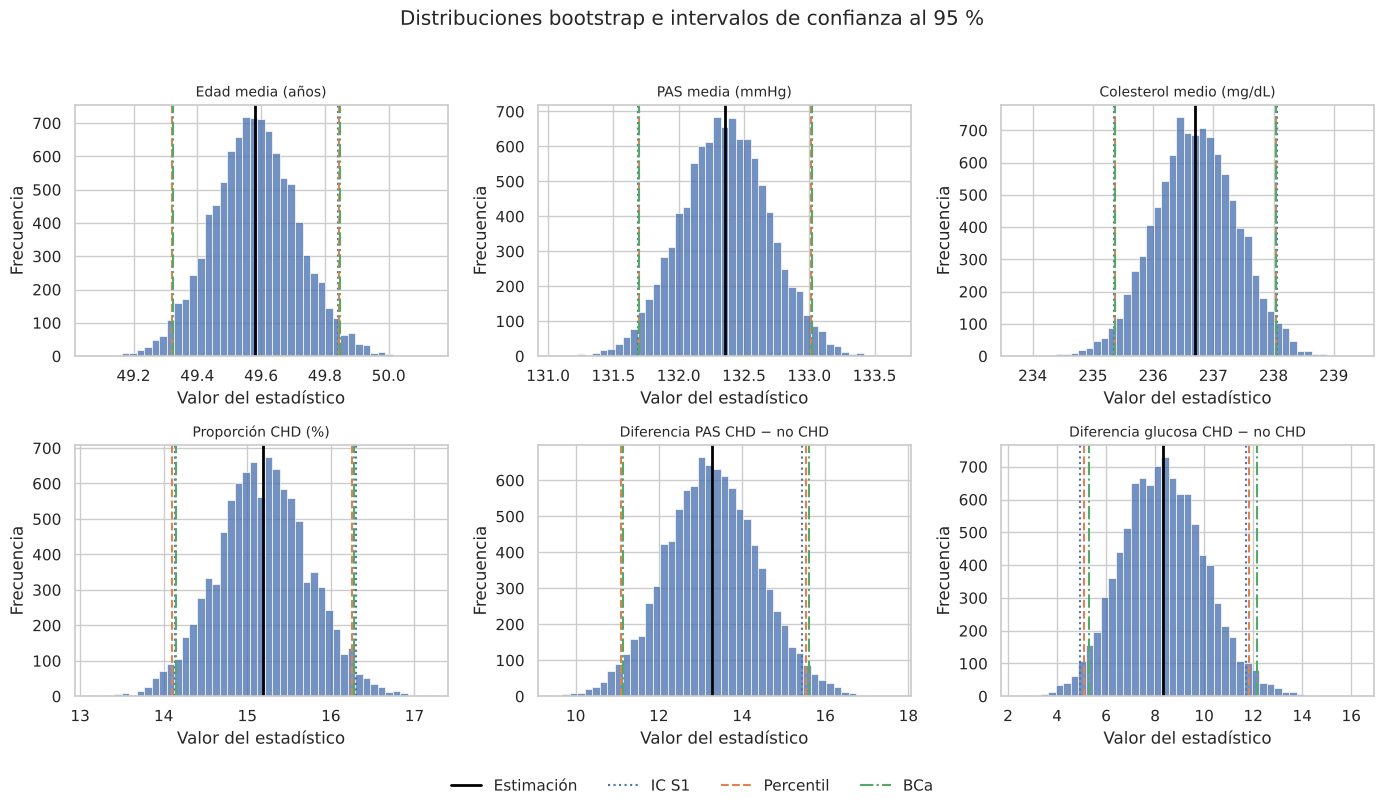

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, r in zip(axes.flat, resultados):
    sns.histplot(r["Distribución"], bins=45, color=COLORES["principal"], alpha=.78, ax=ax)
    ax.axvline(r["Estimación"], color="black", lw=2, label="Estimación")
    ax.axvline(r["S1_inf"], color=COLORES["clasico"], lw=1.5, ls=":", label="IC S1")
    ax.axvline(r["S1_sup"], color=COLORES["clasico"], lw=1.5, ls=":")
    ax.axvline(r["Percentil_inf"], color=COLORES["percentil"], lw=1.5, ls="--", label="Percentil")
    ax.axvline(r["Percentil_sup"], color=COLORES["percentil"], lw=1.5, ls="--")
    ax.axvline(r["BCa_inf"], color=COLORES["bca"], lw=1.5, ls="-.", label="BCa")
    ax.axvline(r["BCa_sup"], color=COLORES["bca"], lw=1.5, ls="-.")
    ax.set_title(r["Parámetro"], fontsize=10)
    ax.set(xlabel="Valor del estadístico", ylabel="Frecuencia")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
plt.suptitle("Distribuciones bootstrap e intervalos de confianza al 95 %", y=.995)
plt.tight_layout(rect=[0, .05, 1, .97])
plt.savefig(FIG / "p1_fig1_distribuciones_bootstrap.png", dpi=200, bbox_inches="tight")
plt.show()


## 1.3 Comparación sistemática con los IC de la S1

Para cada parámetro se comparan los límites y la amplitud de los tres intervalos, y cuánto se desplaza
el IC BCa respecto del IC clásico.

In [5]:
tabla = pd.DataFrame([{k: v for k, v in r.items() if k != "Distribución"} for r in resultados])
tabla["Amplitud_S1"] = tabla["S1_sup"] - tabla["S1_inf"]
tabla["Amplitud_percentil"] = tabla["Percentil_sup"] - tabla["Percentil_inf"]
tabla["Amplitud_BCa"] = tabla["BCa_sup"] - tabla["BCa_inf"]
tabla["Desplazamiento_BCa_vs_S1_inf"] = tabla["BCa_inf"] - tabla["S1_inf"]
tabla["Desplazamiento_BCa_vs_S1_sup"] = tabla["BCa_sup"] - tabla["S1_sup"]
tabla = tabla.set_index("Parámetro")
guardar_tabla(tabla.round(3), "p1_comparacion_ic")


,n,Estimación,S1_inf,S1_sup,Percentil_inf,Percentil_sup,BCa_inf,BCa_sup,Amplitud_S1,Amplitud_percentil,Amplitud_BCa,Desplazamiento_BCa_vs_S1_inf,Desplazamiento_BCa_vs_S1_sup
Parámetro,,,,,,,,,,,,,
Edad media (años),4240,49.5800,49.3200,49.8400,49.3210,49.8450,49.3230,49.8470,0.5200,0.5240,0.5240,0.0030,0.0070
PAS media (mmHg),4240,132.3550,131.6900,133.0200,131.6940,133.0170,131.6970,133.0190,1.3300,1.3230,1.3220,0.0070,-0.0010
Colesterol medio (mg/dL),4190,236.7000,235.3500,238.0500,235.3640,238.0490,235.3640,238.0490,2.7000,2.6850,2.6850,0.0140,-0.0010
Proporción CHD (%),4240,15.1890,14.1400,16.3000,14.1040,16.2500,14.1510,16.2740,2.1600,2.1460,2.1230,0.0110,-0.0260
Diferencia PAS CHD − no CHD,644 / 3596,13.2810,11.1100,15.4500,11.0930,15.5290,11.1400,15.6010,4.3400,4.4360,4.4610,0.0300,0.1510
Diferencia glucosa CHD − no CHD,594 / 3258,8.3290,4.9500,11.7100,5.0990,11.8260,5.3190,12.1580,6.7600,6.7260,6.8390,0.3690,0.4480


## 1.4 Discusión

Los IC percentil y BCa de la edad, la presión sistólica, el colesterol y la proporción de CHD son
prácticamente iguales a los IC clásicos de la S1. Con tamaños muestrales cercanos a 4.000, el
Teorema Central del Límite estabiliza la distribución de las medias; en la proporción, Wilson y
bootstrap también concuerdan.

La diferencia de presión sistólica entre los grupos con y sin CHD, que el docente pidió remuestrear,
también se valida: el IC BCa de [11,14; 15,60] mmHg es casi igual al IC de Welch de la S1 ([11,11; 15,45]).
Su distribución bootstrap es casi simétrica, por lo que los tres métodos coinciden y la magnitud de
13,28 mmHg no depende del supuesto de normalidad.

La glucosa es el caso que exige cautela. La distribución presenta una cola derecha muy marcada y
valores extremos (máximos cercanos a 400 mg/dL), especialmente en el grupo con CHD. Welch construye
un intervalo simétrico alrededor de la diferencia observada mediante un error estándar, mientras que
BCa corrige el sesgo y la aceleración revelados por el remuestreo; por eso su límite superior se
desplaza hacia valores mayores y el intervalo queda asimétrico. No es una contradicción: los tres
intervalos excluyen cero y sostienen que la media de glucosa es mayor en el grupo con CHD, pero BCa
describe mejor la incertidumbre asimétrica. Aun así, el promedio de glucosa es sensible a extremos y
tiene 388 datos faltantes, de modo que conviene informar también medianas o medias recortadas y
repetir el análisis tras un tratamiento explícito de faltantes en la Sumativa 3.
